# 2. Classificação: Iris

150 flores, 4 atributos, 3 espécies. Alvos one-hot, 3 saídas sigmoid e BCE.

In [ ]:
import sys
sys.path.append("..")

import numpy as np

from src.datasets import load_iris, train_val_split, standardize
from src.nn import MLP
from src.optim import Adam
from src.training import train
from src.plots import plot_loss, plot_metric, plot_histograms

PLOTS = "../assets/plots/"

## Dados

80% treino, 20% validação, padronizados com as estatísticas do treino.

In [2]:
X, y = load_iris()
X_train, y_train, X_val, y_val = train_val_split(X, y, val_fraction=0.2, seed=0)
X_train, X_val = standardize(X_train, X_val)

print("train:", X_train.shape, y_train.shape)
print("val:  ", X_val.shape, y_val.shape)

train: (120, 4) (120, 3)
val:   (30, 4) (30, 3)


## Modelo e treino

In [3]:
model = MLP(input_size=4, hidden_sizes=[8], output_size=3,
            hidden_activation="tanh", output_activation="sigmoid", init="xavier")

optimizer = Adam(model.parameters(), lr=0.01)

history = train(model, optimizer, "bce", X_train, y_train, X_val, y_val,
                epochs=100, batch_size=16, metric_name="accuracy")

epoch    1 | train loss 0.5290 | val loss 0.5345 | train accuracy 0.9000 | val accuracy 0.8000
epoch   10 | train loss 0.2332 | val loss 0.3439 | train accuracy 0.9167 | val accuracy 0.8333
epoch   20 | train loss 0.1555 | val loss 0.2672 | train accuracy 0.9667 | val accuracy 0.8667
epoch   30 | train loss 0.1043 | val loss 0.1890 | train accuracy 0.9750 | val accuracy 0.9000
epoch   40 | train loss 0.0725 | val loss 0.1485 | train accuracy 0.9750 | val accuracy 0.9333
epoch   50 | train loss 0.0562 | val loss 0.1182 | train accuracy 0.9667 | val accuracy 0.9333
epoch   60 | train loss 0.0481 | val loss 0.0964 | train accuracy 0.9667 | val accuracy 0.9333
epoch   70 | train loss 0.0429 | val loss 0.0855 | train accuracy 0.9667 | val accuracy 0.9333
epoch   80 | train loss 0.0398 | val loss 0.0897 | train accuracy 0.9667 | val accuracy 0.9333
epoch   90 | train loss 0.0374 | val loss 0.0766 | train accuracy 0.9667 | val accuracy 0.9333
epoch  100 | train loss 0.0359 | val loss 0.0757 |

## Monitoramento

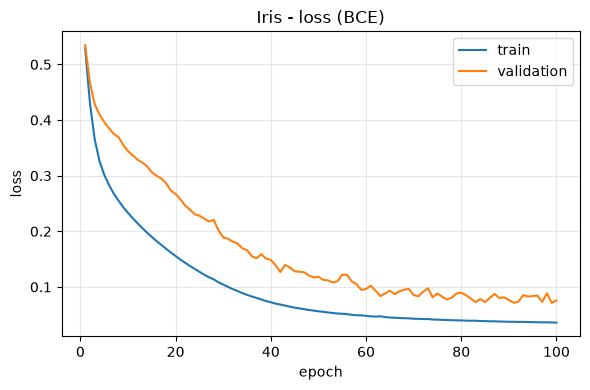

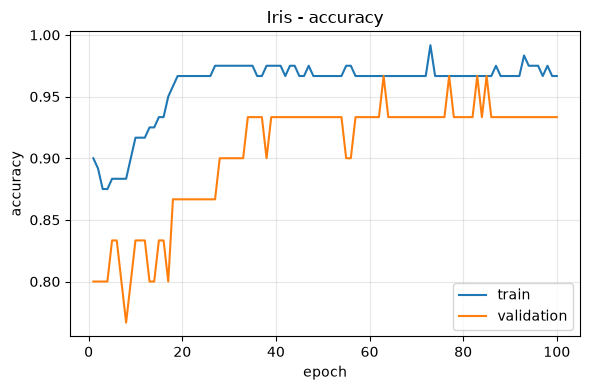

In [4]:
plot_loss(history, title="Iris - loss (BCE)", save_path=PLOTS + "iris_loss.png")
plot_metric(history, "accuracy", title="Iris - accuracy", save_path=PLOTS + "iris_accuracy.png")

Histogramas de ativações e gradientes por camada no início, meio e fim do treino.

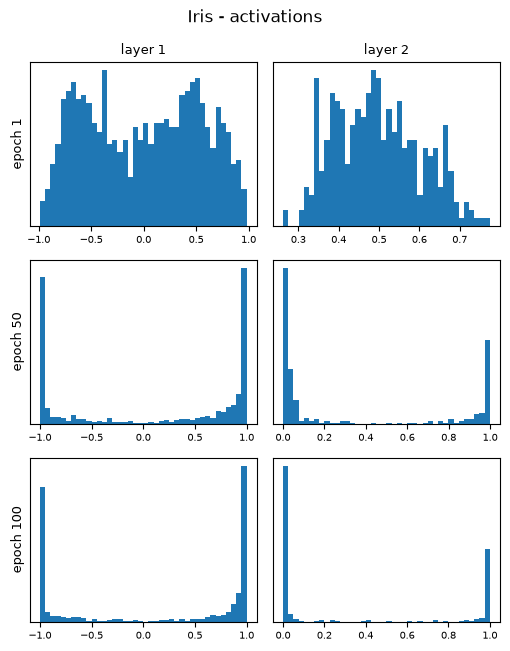

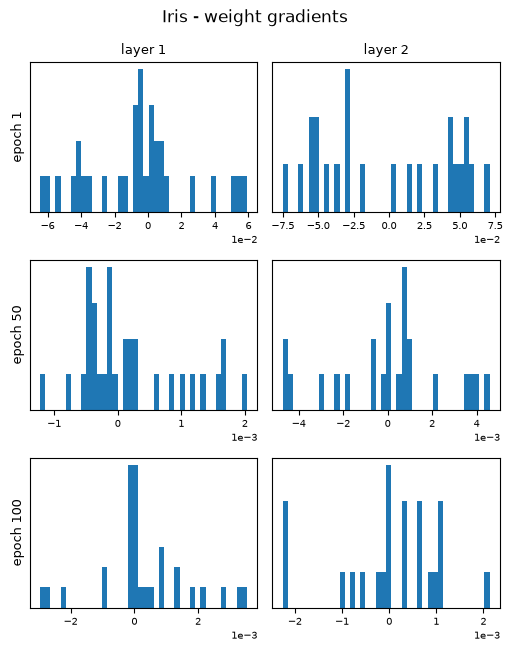

In [5]:
plot_histograms(history, "activations", title="Iris - activations", save_path=PLOTS + "iris_activations.png")
plot_histograms(history, "gradients", title="Iris - weight gradients", save_path=PLOTS + "iris_gradients.png")

## Exportar e importar

O arquivo guarda topologia e pesos; o modelo carregado prevê igual, sem retreinar.

In [6]:
model.save("../models/iris_mlp.npz")

loaded_model = MLP.load("../models/iris_mlp.npz")
print("topology:", loaded_model.config)

difference = np.abs(loaded_model.predict(X_val) - model.predict(X_val)).max()
print("largest difference between original and loaded predictions:", difference)

topology: {'input_size': 4, 'hidden_sizes': [8], 'output_size': 3, 'hidden_activation': 'tanh', 'output_activation': 'sigmoid', 'init': 'xavier', 'init_scale': 0.1, 'seed': 0}
largest difference between original and loaded predictions: 0.0
